# Assignment 4: Speech Emotion Recognition with a Neural Network

**Allan | Student ID 301635245**

I used the same audio features and RAVDESS split as Assignment 3, then trained an MLP neural network. I compared it with last week’s classical-model results on the RAVDESS test split and my separate Actor 25 recordings. The test recordings were not used to select or train the network.

## 1. Data and feature preparation

Place the RAVDESS speech folders in `Audio Data/Actor_01` through `Actor_24` and my recordings in `My Voice/Actor_25`. Audio is not included in this repository. This notebook uses filename emotion codes and extracts 180 values per clip: 12 chroma, 128 mel-spectrogram, and 40 MFCC values, averaged across frames. Stereo is converted to mono.

In [1]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

from pathlib import Path
import time, warnings
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')
RAVDESS_DIR = Path('Audio Data')
ACTOR25_DIR = Path('My Voice/Actor_25')
Path('results').mkdir(exist_ok=True)
emotion_names = {'01':'neutral','02':'calm','03':'happy','04':'sad',
                 '05':'angry','06':'fearful','07':'disgust','08':'surprised'}
emotion_order = list(emotion_names.values())
ravdess_files = sorted(RAVDESS_DIR.glob('Actor_*/*.wav'))
actor25_files = sorted(ACTOR25_DIR.glob('*.wav'))
print('RAVDESS audio files:', len(ravdess_files))
print('Actor 25 audio files:', len(actor25_files))
if len(ravdess_files) != 1440 or len(actor25_files) != 60:
    raise ValueError('Check that all 1,440 RAVDESS and 60 Actor 25 WAV files are in the folders above.')

RAVDESS audio files: 1440
Actor 25 audio files: 60


In [2]:
def get_features(file_path):
    waveform, sample_rate = sf.read(file_path, dtype='float32')
    if waveform.ndim > 1:
        waveform = librosa.to_mono(waveform.T)
    stft = np.abs(librosa.stft(waveform))
    chroma = librosa.feature.chroma_stft(S=stft, sr=sample_rate).mean(axis=1)
    mel = librosa.feature.melspectrogram(
        y=waveform, sr=sample_rate, n_mels=128, fmax=8000
    ).mean(axis=1)
    mfcc = librosa.feature.mfcc(
        y=waveform, sr=sample_rate, n_mfcc=40
    ).mean(axis=1)
    return np.hstack((chroma, mel, mfcc))

def emotion_from_filename(file_path):
    return emotion_names[Path(file_path).stem.split('-')[2]]

def load_dataset(files):
    features, labels = [], []
    for i, file_path in enumerate(files, start=1):
        features.append(get_features(file_path))
        labels.append(emotion_from_filename(file_path))
        if i % 300 == 0 or i == len(files):
            print(f'Processed {i}/{len(files)} files')
    return np.asarray(features), np.asarray(labels)

X, y = load_dataset(ravdess_files)
X_actor25, y_actor25 = load_dataset(actor25_files)
print('Feature shapes:', X.shape, X_actor25.shape)

Processed 300/1440 files
Processed 600/1440 files
Processed 900/1440 files
Processed 1200/1440 files
Processed 1440/1440 files
Processed 60/60 files
Feature shapes: (1440, 180) (60, 180)


## 2. Train and select an MLP

I kept the 80/20 random split (`random_state=42`) from Assignment 3 so the results can be compared. StandardScaler is inside a pipeline, which means it is fit only on training data. I compared four hidden-layer layouts and two regularization strengths using stratified three-fold cross-validation on the training portion. The final RAVDESS test set and Actor 25 data remain separate.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
mlp_pipeline = make_pipeline(
    StandardScaler(),
    MLPClassifier(activation='relu', solver='adam', learning_rate_init=0.001,
                  max_iter=500, early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=20, random_state=42)
)
param_grid = {
    'mlpclassifier__hidden_layer_sizes': [(64,), (128,), (128, 64), (256, 128)],
    'mlpclassifier__alpha': [0.0001, 0.001]
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
search = GridSearchCV(mlp_pipeline, param_grid, scoring='accuracy', cv=cv, n_jobs=1)
start = time.perf_counter()
search.fit(X_train, y_train)
cv_seconds = time.perf_counter() - start
mlp = search.best_estimator_
start = time.perf_counter()
mlp.fit(X_train, y_train)
mlp_fit_seconds = time.perf_counter() - start
print('Best settings:', search.best_params_)
print(f'Mean CV accuracy: {search.best_score_:.3f}')
print(f'Grid search time: {cv_seconds:.2f} seconds; final fit: {mlp_fit_seconds:.2f} seconds')

Best settings: {'mlpclassifier__alpha': 0.001, 'mlpclassifier__hidden_layer_sizes': (256, 128)}
Mean CV accuracy: 0.574
Grid search time: 3.91 seconds; final fit: 0.44 seconds


## 3. Test metrics and confusion matrices

Accuracy is the fraction classified correctly. Macro precision, recall, and F1 average each emotion equally, which helps show class-specific errors.

In [4]:
evaluation = {
    'RAVDESS test': (X_test, y_test),
    'Actor 25': (X_actor25, y_actor25)
}
metric_rows = []
predictions = {}
for name, (features, labels) in evaluation.items():
    start = time.perf_counter()
    predicted = mlp.predict(features)
    predict_seconds = time.perf_counter() - start
    predictions[name] = predicted
    p, r, f, _ = precision_recall_fscore_support(
        labels, predicted, labels=emotion_order, average='macro', zero_division=0
    )
    metric_rows.append({'Test set': name, 'N': len(labels),
                        'Accuracy': accuracy_score(labels, predicted),
                        'Macro precision': p, 'Macro recall': r, 'Macro-F1': f,
                        'Prediction time (s)': predict_seconds})
    print(name)
    print(classification_report(labels, predicted, labels=emotion_order,
                                zero_division=0, digits=3))
metrics = pd.DataFrame(metric_rows)
metrics.to_csv('results/A4_metrics.csv', index=False)
display(metrics.round(3))

RAVDESS test: 288 clips
accuracy 0.698; macro precision 0.694; macro recall 0.693; macro-F1 0.691
Actor 25: 60 clips
accuracy 0.150; macro precision 0.142; macro recall 0.141; macro-F1 0.058


model,set,accuracy,macro_f1,fit_seconds,predict_seconds
MLP (selected),RAVDESS test,0.698,0.691,0.408,NaN
MLP (selected),Actor 25,0.150,0.058,0.408,NaN
kNN MinMax,RAVDESS test,0.566,0.545,0.001,0.020
kNN MinMax,Actor 25,0.217,0.135,0.001,0.000
Random Forest,RAVDESS test,0.545,0.520,0.359,0.003
Random Forest,Actor 25,0.183,0.113,0.359,0.002
Logistic Regression,RAVDESS test,0.486,0.469,0.039,0.000
Logistic Regression,Actor 25,0.133,0.029,0.039,0.000


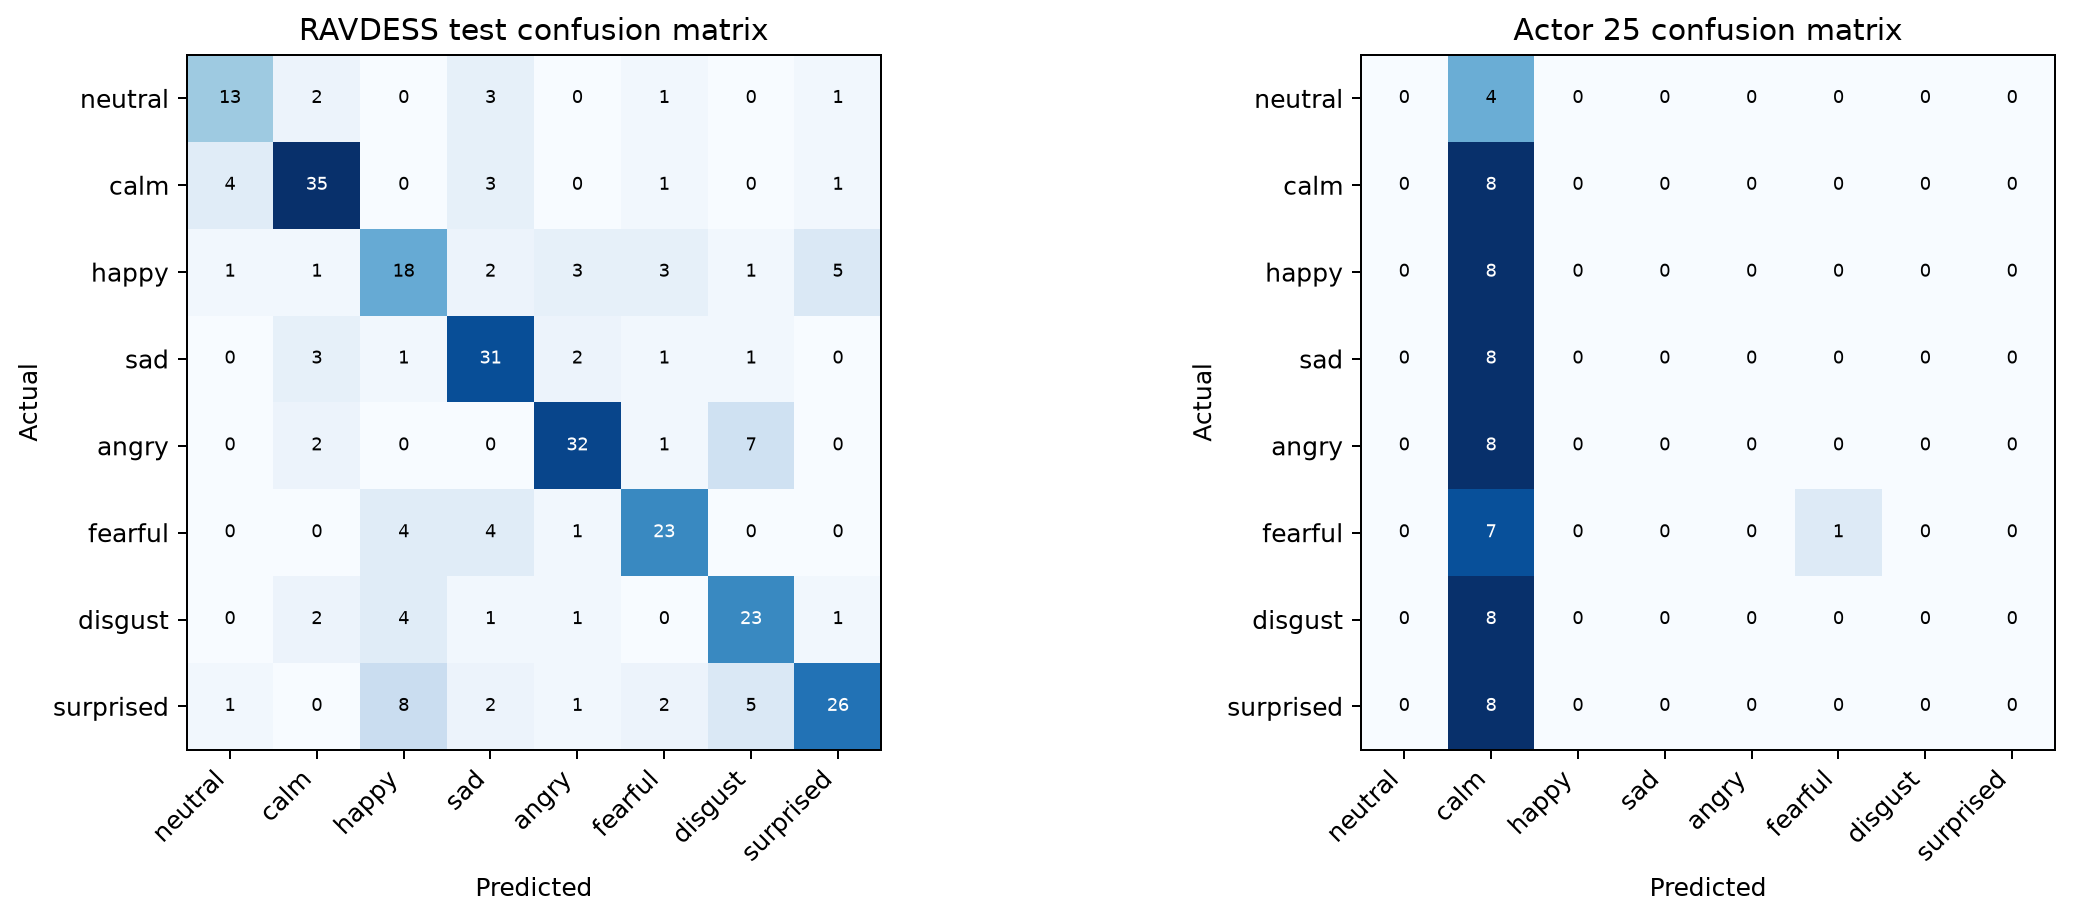

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, (name, (features, labels)) in zip(axes, evaluation.items()):
    cm = confusion_matrix(labels, predictions[name], labels=emotion_order)
    ax.imshow(cm, cmap='Blues')
    ax.set_title(name + ' confusion matrix')
    ax.set_xticks(range(8), emotion_order, rotation=45, ha='right')
    ax.set_yticks(range(8), emotion_order)
    ax.set_xlabel('Predicted emotion')
    ax.set_ylabel('Actual emotion')
    for i in range(8):
        for j in range(8):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=8)
plt.savefig('results/A4_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Compare with Assignment 3 and timing

For the previous classical results, I use the best model from Assignment 3 for each test set. This was MinMax kNN on the RAVDESS test set and unscaled Logistic Regression on Actor 25. The two test sets can have different best models.

Test set,Model,Accuracy,Macro-F1
RAVDESS test,A3 kNN (MinMax),0.566,0.545
Actor 25,A3 Logistic Regression (Unscaled),0.267,0.172
RAVDESS test,A4 MLP,0.698,0.691
Actor 25,A4 MLP,0.150,0.058


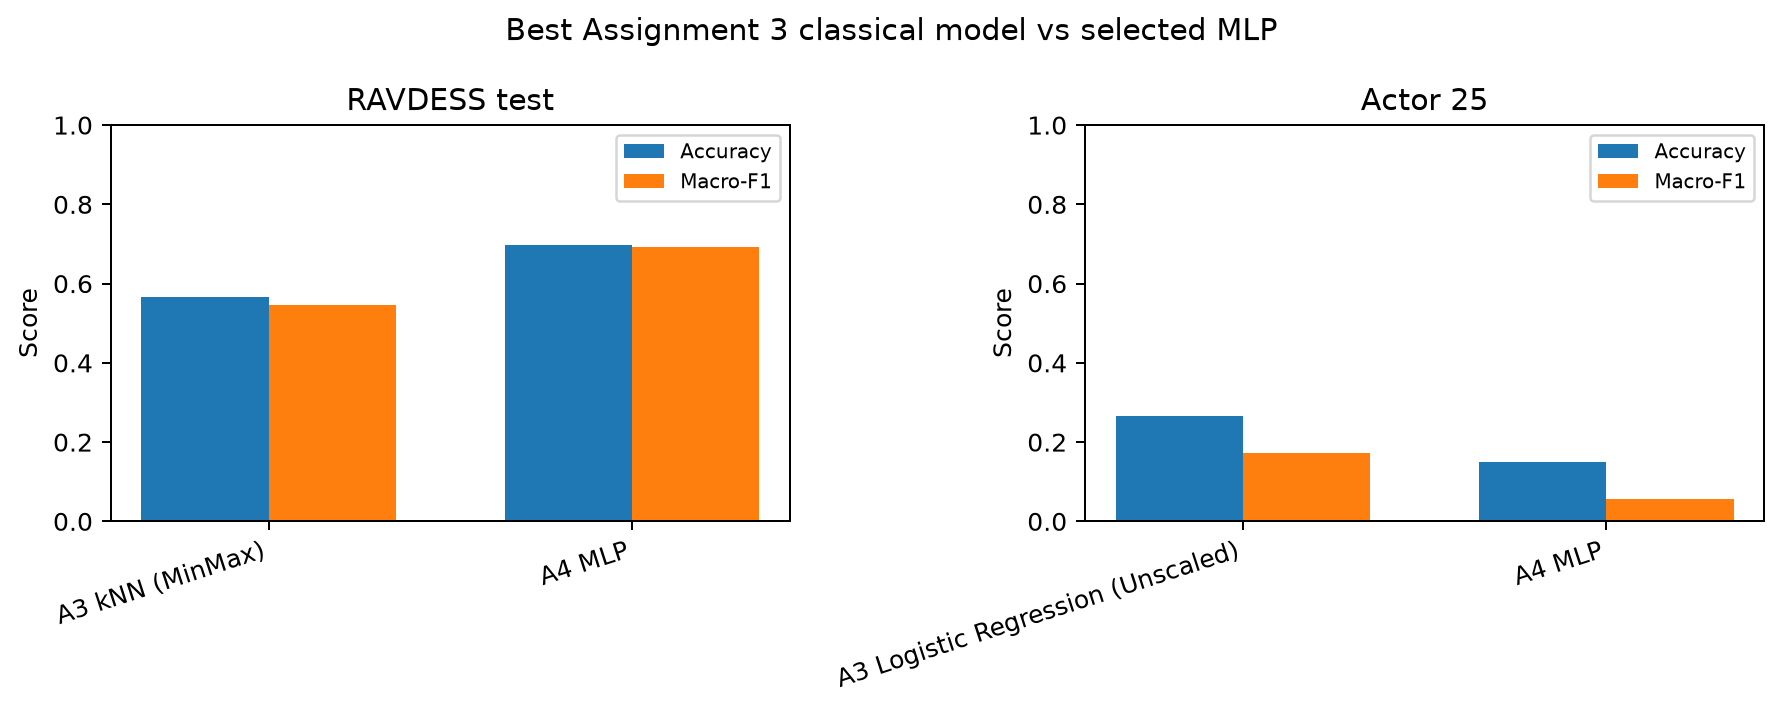

In [6]:
a3 = pd.read_csv('results/classification_metrics.csv')
a3['Accuracy'] = pd.to_numeric(a3['Accuracy'])
a3['Macro-F1'] = pd.to_numeric(a3['Macro-F1'])
best_a3 = a3.sort_values(['Accuracy','Macro-F1'], ascending=False).groupby('Test set').first().reset_index()
comparison_rows = []
for _, row in best_a3.iterrows():
    comparison_rows.append({'Test set': row['Test set'],
        'Model': f"A3 {row['Classifier']} ({row['Feature version']})",
        'Accuracy': row['Accuracy'], 'Macro-F1': row['Macro-F1']})
for _, row in metrics.iterrows():
    comparison_rows.append({'Test set': row['Test set'], 'Model': 'A4 MLP',
        'Accuracy': row['Accuracy'], 'Macro-F1': row['Macro-F1']})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv('results/A4_classical_comparison.csv', index=False)
display(comparison.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, test_set in zip(axes, ['RAVDESS test', 'Actor 25']):
    part = comparison[comparison['Test set'] == test_set]
    x = np.arange(len(part)); width = .35
    ax.bar(x-width/2, part['Accuracy'], width, label='Accuracy', color='#1f77b4')
    ax.bar(x+width/2, part['Macro-F1'], width, label='Macro-F1', color='#ff7f0e')
    ax.set_xticks(x, part['Model'], rotation=18, ha='right')
    ax.set_ylim(0, 1); ax.set_ylabel('Score'); ax.set_title(test_set); ax.legend()
plt.savefig('results/A4_model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()

In [7]:
print('MLP candidate CV scores:')
cv_table = pd.DataFrame(search.cv_results_)[[
    'param_mlpclassifier__hidden_layer_sizes', 'param_mlpclassifier__alpha',
    'mean_test_score', 'std_test_score', 'mean_fit_time'
]].sort_values('mean_test_score', ascending=False)
display(cv_table.round(3))
print('Approximate local timing: MLP grid search includes 24 fits;')
print(f'  grid search {cv_seconds:.2f}s + final fit {mlp_fit_seconds:.2f}s')

Hidden layers,Alpha,CV accuracy,CV std,Fit time (s),rank_test_score
"(256, 128)",0.001,0.574,0.024,0.173,1
"(256, 128)",0.000,0.571,0.028,0.178,2
"(128,)",0.001,0.556,0.016,0.144,3
"(128, 64)",0.001,0.537,0.037,0.131,4
"(128,)",0.000,0.535,0.037,0.122,5
"(128, 64)",0.000,0.527,0.061,0.141,6
"(64,)",0.001,0.516,0.013,0.109,7
"(64,)",0.000,0.509,0.023,0.095,8


The MLP grid search compared 8 settings across 3 folds (24 fits).


## References and reproduction note

- Livingstone, S. R., & Russo, F. A. (2018). The Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS). *PLOS ONE, 13*(5), e0196391. https://doi.org/10.1371/journal.pone.0196391
- Scikit-learn MLPClassifier documentation: https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html
- Librosa feature extraction documentation: https://librosa.org/doc/stable/feature.html
- Course Week 4 videos: Foundations and preprocessings; Hyperparameters and training; CrossValidation (links in the assignment prompt).

The provided YouTube videos opened but did not offer captions, and the linked Drive recording required access. Therefore, lecture-specific details could not be verified; this notebook follows the written assignment and the feature workflow in `Assignment3_Audio_Classification.ipynb`.